# 07. ViT-Small supervised field adaptation

V1 adapts the existing PlantVillage-trained ViT-Small using Field Adapt Train (370 images) and selects by macro-F1 on the verified Field Dev (92 images). Lab Validation (1,341 images) measures source retention before adaptation and after selection.

The protocol matches ResNet18's two head epochs, up to six final-block epochs, seed 42, and mild augmentation strengths. ViT retains its own preprocessing, batch size, and trainable layers. The comparison concerns these configurations rather than an isolated architecture effect. Field Dev supports selection; the previously inspected 47-image Field Test is used only for image-fingerprint contamination checks, without model inference.

## Runtime and source

The recorded run uses a Colab Tesla T4, timm `1.0.26`, and source revision `6d9de4f4a8a470a616e798994fde7e5a956a72e4`. Setup synchronizes the checkout and checks CUDA.

In [1]:
%pip install -q "timm==1.0.26" datasets pandas scikit-learn matplotlib pillow ImageHash

In [2]:
from pathlib import Path
import subprocess, sys
import torch

REPO_URL = "https://github.com/thutrang147/plant-disease-diagnosis.git"
PROJECT_ROOT = Path("/content/plant-disease-diagnosis")
if not PROJECT_ROOT.is_dir():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"], check=True)
GIT_SHA = subprocess.check_output(
    ["git", "-C", str(PROJECT_ROOT), "rev-parse", "HEAD"], text=True
).strip()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

assert torch.cuda.is_available(), "Please select a Colab GPU runtime before training."
print("GPU:", torch.cuda.get_device_name(0))
print("Git commit:", GIT_SHA)

GPU: Tesla T4
Git commit: 6d9de4f4a8a470a616e798994fde7e5a956a72e4


## Source checkpoint and configuration

The experiment loads `vit_small_baseline/vit_small_lab_best.pt` from Drive. Architecture, pretraining tag, class order, and the stored preprocessing configuration are checked before use. The source SHA-256 is recorded alongside seed 42 and batch size 16.

In [3]:
from google.colab import drive
import hashlib, json, random

import imagehash
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import timm
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torch.amp import autocast, GradScaler
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)
from src.dataset import PlantDiseaseDataset

drive.mount("/content/drive")

SEED = 42
BATCH_SIZE = 16                  # Compatible with typical Colab T4 memory
HEAD_EPOCHS = 2
LAST_BLOCK_EPOCHS = 6
EARLY_STOP_PATIENCE = 3
HEAD_LR = 1e-4
BACKBONE_LR = 1e-5
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0
MODEL_NAME = "vit_small_patch16_224.augreg_in1k"
DEVICE = torch.device("cuda")
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
DRIVE_ROOT = Path("/content/drive/MyDrive/plant-disease-diagnosis")
SOURCE_CHECKPOINT = DRIVE_ROOT / "vit_small_baseline" / "vit_small_lab_best.pt"
OUTPUT_ROOT = DRIVE_ROOT / "vit_small_field_adaptation_verified"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

assert SOURCE_CHECKPOINT.is_file(), f"Missing ViT checkpoint: {SOURCE_CHECKPOINT}"
label_map = json.loads((SPLITS_DIR / "label_map.json").read_text(encoding="utf-8"))
CLASS_NAMES = [name for name, idx in sorted(label_map.items(), key=lambda kv: kv[1])]
assert len(CLASS_NAMES) == 5 and sorted(label_map.values()) == list(range(5))

source_ckpt = torch.load(SOURCE_CHECKPOINT, map_location="cpu", weights_only=True)
assert source_ckpt.get("architecture") == MODEL_NAME, "ViT architecture mismatch"
assert source_ckpt.get("class_names") == CLASS_NAMES, "Checkpoint class order mismatch"
assert source_ckpt.get("pretrained_weights") == "augreg_in1k", "Pretraining tag mismatch"
assert "preprocessing_config" in source_ckpt, "Missing ViT preprocessing configuration"
DATA_CONFIG = source_ckpt["preprocessing_config"]
assert tuple(DATA_CONFIG["input_size"]) == (3, 224, 224)

SOURCE_CKPT_SHA256 = hashlib.sha256(SOURCE_CHECKPOINT.read_bytes()).hexdigest()

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

reset_seed()
print("timm:", timm.__version__)
print("ViT checkpoint:", SOURCE_CHECKPOINT)
print("ViT source Lab Val macro-F1:", source_ckpt.get("best_val_macro_f1"))
print("Classes:", CLASS_NAMES)
print("Preprocessing:", DATA_CONFIG)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
timm: 1.0.26
ViT checkpoint: /content/drive/MyDrive/plant-disease-diagnosis/vit_small_baseline/vit_small_lab_best.pt
ViT source Lab Val macro-F1: 0.996618849407717
Classes: ['Healthy', 'Early Blight', 'Late Blight', 'Bacterial Spot', 'Septoria Leaf Spot']
Preprocessing: {'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'crop_pct': 0.9, 'crop_mode': 'center'}


## Manifest integrity and provenance

The notebook requires the 370/92/14 adaptation/development/quarantine allocation and Field Dev SHA-256 `2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe0b320a28a6aae960e9`. Checks cover original-row accounting, labels, exact hashes, pHash groups, and separation from original Field Test row IDs.

In [4]:
required_files = [
    "field_train.csv", "field_adapt_train.csv", "field_dev.csv",
    "field_test.csv", "field_quarantined_train.csv", "field_dev_protocol.json",
    "lab_val.csv", "label_map.json",
]
for filename in required_files:
    assert (SPLITS_DIR / filename).is_file(), (
        f"Missing {filename}. Push the verified split files from your Mac to GitHub first."
    )
protocol = json.loads((SPLITS_DIR / "field_dev_protocol.json").read_text(encoding="utf-8"))
assert protocol.get("strategy", "").startswith("Perceptual pHash connected-component grouping")
assert protocol["source_dataset"] == "geraldmc/plantdoc-full"
assert protocol["source_revision"] == "v0.1.0"
assert protocol["phash_threshold"] == 4

manifests = {
    name: pd.read_csv(SPLITS_DIR / f"{name}.csv")
    for name in ("field_train", "field_adapt_train", "field_dev", "field_test", "lab_val")
}
quarantine_df = pd.read_csv(SPLITS_DIR / "field_quarantined_train.csv")
train_df = manifests["field_adapt_train"]
dev_df = manifests["field_dev"]
test_df = manifests["field_test"]
assert len(test_df) == 47, "Original Field Test count changed"
assert len(manifests["field_train"]) == protocol["original_field_train_images"]
assert len(train_df) == protocol["adaptation_train_images"]
assert len(dev_df) == protocol["development_images"]
assert len(quarantine_df) == protocol["quarantined_total_train_images"]
assert len(train_df) + len(dev_df) + len(quarantine_df) == len(manifests["field_train"])

for name in ("field_adapt_train", "field_dev", "field_test"):
    frame = manifests[name]
    assert (frame["source"] == "plantdoc").all(), name
    assert frame["row_id"].is_unique, name
    assert set(frame["label_id"]) == set(range(5)), name
    assert (frame["class_name"].map(label_map) == frame["label_id"]).all(), name
for frame in (train_df, dev_df, quarantine_df):
    assert {"exact_hash", "phash", "group_id"}.issubset(frame.columns)
assert set(train_df["group_id"]).isdisjoint(dev_df["group_id"])
assert set(train_df["group_id"]).isdisjoint(quarantine_df["group_id"])
assert set(dev_df["group_id"]).isdisjoint(quarantine_df["group_id"])
assert set(train_df["row_id"]).isdisjoint(dev_df["row_id"])
assert set(train_df["row_id"]).isdisjoint(test_df["row_id"])
assert set(dev_df["row_id"]).isdisjoint(test_df["row_id"])
assert (
    set(train_df["row_id"]) | set(dev_df["row_id"]) | set(quarantine_df["row_id"])
    == set(manifests["field_train"]["row_id"])
)
assert set(train_df["exact_hash"]).isdisjoint(dev_df["exact_hash"])

SPLIT_HASHES = {
    name: hashlib.sha256((SPLITS_DIR / f"{name}.csv").read_bytes()).hexdigest()
    for name in ("field_adapt_train", "field_dev", "lab_val")
}
print("Verified split:", len(train_df), "adapt train,", len(dev_df),
      "dev,", len(quarantine_df), "quarantine,", len(test_df), "untouched field test")
print("Field Dev SHA256:", SPLIT_HASHES["field_dev"])
EXPECTED_FIELD_DEV_SHA256 = "2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe0b320a28a6aae960e9"
assert SPLIT_HASHES["field_dev"] == EXPECTED_FIELD_DEV_SHA256, (
    "Field Dev has changed from the verified ResNet18 comparison. "
    "Do not compare until the same verified split is restored or all models are re-evaluated."
)
assert (len(train_df), len(dev_df), len(quarantine_df)) == (370, 92, 14), (
    "This notebook expects the validated 370/92/14 split. "
    "Review the manifest protocol before training."
)
print(pd.crosstab(
    pd.concat([train_df.assign(partition="adapt_train"),
               dev_df.assign(partition="dev")], ignore_index=True)["class_name"],
    pd.concat([train_df.assign(partition="adapt_train"),
               dev_df.assign(partition="dev")], ignore_index=True)["partition"],
))
print("Verified Field Dev manifest matches the previously evaluated ResNet18 split.")

Verified split: 370 adapt train, 92 dev, 14 quarantine, 47 untouched field test
Field Dev SHA256: 2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe0b320a28a6aae960e9
partition           adapt_train  dev
class_name                          
Bacterial Spot               80   18
Early Blight                 60   16
Healthy                      44   11
Late Blight                  79   20
Septoria Leaf Spot          107   27
Verified Field Dev manifest matches the previously evaluated ResNet18 split.


## Architecture-specific preprocessing

Field Adapt Train uses mild crop, flip, and color-jitter augmentation with bicubic interpolation and the source ViT normalization. Field Dev and Lab Validation use the deterministic timm transform stored in the source checkpoint.

In [5]:
val_transform = timm.data.create_transform(**DATA_CONFIG, is_training=False)
mean, std = tuple(DATA_CONFIG["mean"]), tuple(DATA_CONFIG["std"])
train_transform = transforms.Compose([
    transforms.Resize(256, interpolation=InterpolationMode.BICUBIC),
    transforms.RandomResizedCrop(
        224, scale=(0.85, 1.0), ratio=(0.90, 1.10),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10),
    ], p=0.35),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

adapt_train_ds = PlantDiseaseDataset(SPLITS_DIR / "field_adapt_train.csv", transform=train_transform)
field_dev_ds = PlantDiseaseDataset(SPLITS_DIR / "field_dev.csv", transform=val_transform)
lab_val_ds = PlantDiseaseDataset(SPLITS_DIR / "lab_val.csv", transform=val_transform)

train_loader = DataLoader(adapt_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
field_dev_loader = DataLoader(field_dev_ds, batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)
lab_val_loader = DataLoader(lab_val_ds, batch_size=BATCH_SIZE, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)

xb, yb = next(iter(train_loader))
assert tuple(xb.shape[1:]) == (3, 224, 224)
print("Field Adapt Train:", len(adapt_train_ds))
print("Field Dev:", len(field_dev_ds))
print("Lab Validation:", len(lab_val_ds))
print("Batch shape:", tuple(xb.shape))
print("Evaluation preprocessing:", val_transform)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Field Adapt Train: 370
Field Dev: 92
Lab Validation: 1341
Batch shape: (16, 3, 224, 224)
Evaluation preprocessing: Compose(
    Resize(size=248, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.5000, 0.5000, 0.5000]), std=tensor([0.5000, 0.5000, 0.5000]))
)


## Image-content audit

The audit recomputes RGB SHA-256 and pHash against the source dataset and validates original labels. The saved checks report zero exact adaptation/development overlap and zero cross-partition pHash candidate pairs at distance ≤ 4, including checks against original Field Test. These are fingerprint checks rather than Field Test model predictions; residual duplicates outside the screening criterion remain possible.

In [6]:
source = adapt_train_ds.source_datasets["plantdoc"]

def image_fingerprints(frame):
    rows = []
    for row in frame.itertuples(index=False):
        sample = source[int(row.row_id)]
        if sample["class_label"] != row.original_class:
            raise ValueError(f"Upstream PlantDoc class changed for row_id {row.row_id}")
        image = sample["image"].convert("RGB")
        digest = hashlib.sha256(
            f"{image.size}".encode("utf-8") + image.tobytes()
        ).hexdigest()
        rows.append({
            "row_id": int(row.row_id),
            "exact_hash": digest,
            "phash": imagehash.phash(image),
        })
    return rows

train_fp = image_fingerprints(train_df)
dev_fp = image_fingerprints(dev_df)
for name, frame, records in (
    ("field_adapt_train", train_df, train_fp),
    ("field_dev", dev_df, dev_fp),
):
    expected = dict(zip(frame["row_id"], frame["exact_hash"]))
    for item in records:
        assert item["exact_hash"] == expected[item["row_id"]], (
            f"{name}: source image changed at row_id={item['row_id']}"
        )

assert set(x["exact_hash"] for x in train_fp).isdisjoint(
    x["exact_hash"] for x in dev_fp
), "Exact images overlap between Adapt Train and Field Dev"
threshold = int(protocol["phash_threshold"])
train_dev_near = [
    (a["row_id"], b["row_id"], a["phash"] - b["phash"])
    for a in train_fp for b in dev_fp
    if a["phash"] - b["phash"] <= threshold
]
assert not train_dev_near, f"Train/Dev near-duplicates found: {train_dev_near[:8]}"

test_fp = image_fingerprints(test_df)
train_dev_vs_test = [
    (a["row_id"], b["row_id"], a["phash"] - b["phash"])
    for a in train_fp + dev_fp for b in test_fp
    if a["phash"] - b["phash"] <= threshold
]
assert not train_dev_vs_test, (
    f"Near-duplicate leakage against original Field Test: {train_dev_vs_test[:8]}"
)
print("Image fingerprint audit passed.")
print("Cross-partition exact duplicates: 0")
print("Cross-partition pHash near-duplicates (distance <= 4): 0")
print("No Field Test model inference performed.")

Image fingerprint audit passed.
Cross-partition exact duplicates: 0
Cross-partition pHash near-duplicates (distance <= 4): 0
No Field Test model inference performed.


## Trainable layers and selection criterion

Stage 1 updates the head. Stage 2 updates the final transformer block, final normalization, and head, while earlier blocks and patch embedding remain frozen. The source model remains a candidate if adaptation does not improve five-class Field Dev macro-F1. Lab Validation is a retention diagnostic, not a selection criterion.

In [7]:
criterion = nn.CrossEntropyLoss()
LABEL_IDS = list(range(len(CLASS_NAMES)))


def load_source_vit():
    model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=len(CLASS_NAMES))
    model.load_state_dict(source_ckpt["model_state_dict"], strict=True)
    assert isinstance(model.get_classifier(), nn.Linear), "Unexpected ViT classifier structure"
    return model.to(DEVICE)


def set_trainable(model, stage):
    last_block_prefix = f"blocks.{len(model.blocks) - 1}."
    for name, parameter in model.named_parameters():
        head = name.startswith("head.")
        final_block = name.startswith(last_block_prefix)
        final_norm = name.startswith("norm.") or name.startswith("fc_norm.")
        if stage == "head":
            parameter.requires_grad = head
        elif stage == "last_block":
            parameter.requires_grad = head or final_block or final_norm
        else:
            raise ValueError(stage)
    trainable = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
    assert trainable and any(name.startswith("head.") for name in trainable)
    print(f"{stage}: {sum(p.numel() for p in model.parameters() if p.requires_grad):,} "
          f"trainable parameters across {len(trainable)} tensors")


def make_optimizer(model, stage):
    if stage == "head":
        return torch.optim.AdamW(model.get_classifier().parameters(),
                                 lr=HEAD_LR, weight_decay=WEIGHT_DECAY)
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    last_block_params = [p for p in model.parameters()
                         if p.requires_grad and id(p) not in head_ids]
    assert last_block_params
    return torch.optim.AdamW([
        {"params": last_block_params, "lr": BACKBONE_LR},
        {"params": model.get_classifier().parameters(), "lr": HEAD_LR},
    ], weight_decay=WEIGHT_DECAY)


def run_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
                loss = criterion(logits, targets)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total_loss += float(loss.detach()) * len(targets)
        y_true.extend(targets.detach().cpu().tolist())
        y_pred.extend(logits.detach().argmax(dim=1).cpu().tolist())
    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0
        )),
    }


def infer(model, loader):
    model.eval()
    y_true, y_pred, scores = [], [], []
    with torch.inference_mode():
        for images, targets in loader:
            with autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images.to(DEVICE, non_blocking=True))
            confidence, preds = torch.softmax(logits.float(), dim=1).max(1)
            y_true.extend(targets.tolist())
            y_pred.extend(preds.cpu().tolist())
            scores.extend(confidence.cpu().tolist())
    return np.asarray(y_true), np.asarray(y_pred), np.asarray(scores)

model = load_source_vit()
print("Total ViT parameters:", sum(p.numel() for p in model.parameters()))
model.cpu()
del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Total ViT parameters: 21667589


## Saved optimization trajectory

The source Field Dev macro-F1 is 0.2677. Head-only adaptation reaches 0.3179; final-block adaptation selects epoch 5 at 0.3838. One ViT source checkpoint is evaluated; there is no separately trained geometric ViT control in this study.

In [8]:
EXPERIMENT_NAME = "V1_lab_baseline"
EXPERIMENT_DIR = OUTPUT_ROOT / EXPERIMENT_NAME
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = EXPERIMENT_DIR / "vit_small_field_best.pt"
HISTORY_PATH = EXPERIMENT_DIR / "training_history.csv"


def save_best(model, phase, epoch, dev_f1):
    torch.save({
        "model_state_dict": model.state_dict(),
        "architecture": MODEL_NAME,
        "pretrained_weights": "augreg_in1k",
        "class_names": CLASS_NAMES,
        "preprocessing_config": DATA_CONFIG,
        "source_checkpoint": str(SOURCE_CHECKPOINT),
        "source_checkpoint_sha256": SOURCE_CKPT_SHA256,
        "experiment": EXPERIMENT_NAME,
        "selected_phase": phase,
        "selected_epoch": int(epoch),
        "best_field_dev_macro_f1": float(dev_f1),
        "seed": SEED,
        "git_commit": GIT_SHA,
        "field_adapt_train_sha256": SPLIT_HASHES["field_adapt_train"],
        "field_dev_sha256": SPLIT_HASHES["field_dev"],
        "lab_val_sha256": SPLIT_HASHES["lab_val"],
    }, BEST_PATH)

reset_seed()
model = load_source_vit()
scaler = GradScaler("cuda")
before_field = run_epoch(model, field_dev_loader)
before_lab = run_epoch(model, lab_val_loader)
source_true, source_pred, source_conf = infer(model, field_dev_loader)

best_f1 = before_field["macro_f1"]
selected_phase = "source_unadapted"
selected_epoch = 0
save_best(model, selected_phase, selected_epoch, best_f1)
history = [{
    "phase": selected_phase, "epoch": 0,
    "train_loss": np.nan, "train_macro_f1": np.nan,
    "dev_loss": before_field["loss"],
    "dev_accuracy": before_field["accuracy"],
    "dev_macro_f1": before_field["macro_f1"],
}]
print(f"Source ViT: Field Dev macro-F1={best_f1:.4f}; "
      f"Lab Val macro-F1={before_lab['macro_f1']:.4f}")

for stage, n_epochs in (("head", HEAD_EPOCHS), ("last_block", LAST_BLOCK_EPOCHS)):
    if stage == "last_block":
        selected = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
        model.load_state_dict(selected["model_state_dict"], strict=True)
    set_trainable(model, stage)
    optimizer = make_optimizer(model, stage)
    no_improvement = 0
    for epoch in range(1, n_epochs + 1):
        train_metrics = run_epoch(model, train_loader, optimizer=optimizer, scaler=scaler)
        dev_metrics = run_epoch(model, field_dev_loader)
        history.append({
            "phase": stage, "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_macro_f1": train_metrics["macro_f1"],
            "dev_loss": dev_metrics["loss"],
            "dev_accuracy": dev_metrics["accuracy"],
            "dev_macro_f1": dev_metrics["macro_f1"],
        })
        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        if dev_metrics["macro_f1"] > best_f1 + 1e-6:
            best_f1 = dev_metrics["macro_f1"]
            selected_phase, selected_epoch = stage, epoch
            save_best(model, selected_phase, selected_epoch, best_f1)
            no_improvement = 0
        else:
            no_improvement += 1
        print(f"{stage} {epoch}/{n_epochs}: "
              f"train F1={train_metrics['macro_f1']:.4f}, "
              f"Field Dev F1={dev_metrics['macro_f1']:.4f}, "
              f"best={best_f1:.4f}")
        if stage == "last_block" and no_improvement >= EARLY_STOP_PATIENCE:
            print("Early stopping after three consecutive non-improving final-block epochs.")
            break

pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
print("Selected:", selected_phase, "epoch", selected_epoch,
      f"| Field Dev macro-F1={best_f1:.4f}")
print("Checkpoint:", BEST_PATH)

Source ViT: Field Dev macro-F1=0.2677; Lab Val macro-F1=0.9966
head: 1,925 trainable parameters across 2 tensors
head 1/2: train F1=0.2885, Field Dev F1=0.3179, best=0.3179
head 2/2: train F1=0.3202, Field Dev F1=0.3139, best=0.3179
last_block: 1,777,157 trainable parameters across 16 tensors
last_block 1/6: train F1=0.3302, Field Dev F1=0.3000, best=0.3179
last_block 2/6: train F1=0.4009, Field Dev F1=0.3289, best=0.3289
last_block 3/6: train F1=0.4627, Field Dev F1=0.3480, best=0.3480
last_block 4/6: train F1=0.4709, Field Dev F1=0.3695, best=0.3695
last_block 5/6: train F1=0.5121, Field Dev F1=0.3838, best=0.3838
last_block 6/6: train F1=0.5190, Field Dev F1=0.3838, best=0.3838
Selected: last_block epoch 5 | Field Dev macro-F1=0.3838
Checkpoint: /content/drive/MyDrive/plant-disease-diagnosis/vit_small_field_adaptation_verified/V1_lab_baseline/vit_small_field_best.pt


## Selected-checkpoint evaluation

The saved best state and its source/split hashes are checked before reporting predictions. Field Dev accuracy is 0.3913 (36/92), compared with 0.4022 (37/92) before adaptation, despite higher macro-F1. The class report therefore matters alongside the aggregate score.

=== Selected ViT Field Dev report ===
                     precision    recall  f1-score   support

           Healthy     0.4167    0.4545    0.4348        11
      Early Blight     0.2857    0.2500    0.2667        16
       Late Blight     0.5000    0.4500    0.4737        20
    Bacterial Spot     0.2174    0.2778    0.2439        18
Septoria Leaf Spot     0.5200    0.4815    0.5000        27

          accuracy                         0.3913        92
         macro avg     0.3880    0.3828    0.3838        92
      weighted avg     0.4033    0.3913    0.3958        92



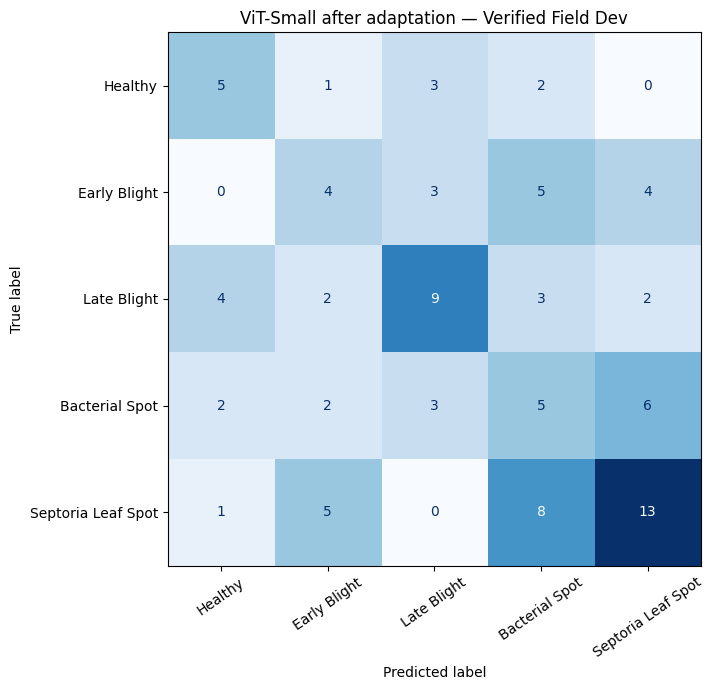

In [9]:
best_ckpt = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
assert best_ckpt["source_checkpoint_sha256"] == SOURCE_CKPT_SHA256
assert best_ckpt["field_dev_sha256"] == SPLIT_HASHES["field_dev"]
model.load_state_dict(best_ckpt["model_state_dict"], strict=True)
model.eval()

after_field = run_epoch(model, field_dev_loader)
after_lab = run_epoch(model, lab_val_loader)
y_true, y_pred, scores = infer(model, field_dev_loader)
assert np.array_equal(source_true, y_true)
assert np.isclose(after_field["macro_f1"], best_f1, atol=1e-9)

source_report = classification_report(
    source_true, source_pred, labels=LABEL_IDS, target_names=CLASS_NAMES,
    zero_division=0, digits=4,
)
selected_report = classification_report(
    y_true, y_pred, labels=LABEL_IDS, target_names=CLASS_NAMES,
    zero_division=0, digits=4,
)
(EXPERIMENT_DIR / "field_dev_before_classification_report.txt").write_text(source_report, encoding="utf-8")
(EXPERIMENT_DIR / "field_dev_classification_report.txt").write_text(selected_report, encoding="utf-8")
print("=== Selected ViT Field Dev report ===\n", selected_report)

predictions = dev_df[["source", "row_id", "class_name", "label_id"]].copy()
predictions["source_predicted_label_id"] = source_pred
predictions["source_confidence"] = source_conf
predictions["predicted_label_id"] = y_pred
predictions["predicted_class"] = [CLASS_NAMES[i] for i in y_pred]
predictions["confidence"] = scores
predictions["correct_before"] = source_pred == y_true
predictions["correct_after"] = y_pred == y_true
predictions.to_csv(EXPERIMENT_DIR / "field_dev_predictions.csv", index=False)

matrix = confusion_matrix(y_true, y_pred, labels=LABEL_IDS)
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35,
)
ax.set_title("ViT-Small after adaptation — Verified Field Dev")
fig.tight_layout()
fig.savefig(EXPERIMENT_DIR / "field_dev_confusion_matrix.png", dpi=160)
plt.show()
plt.close(fig)

## Field performance and source retention

Field Dev macro-F1 rises from 0.2677 to 0.3838, while Lab Validation macro-F1 declines from 0.9966 to 0.9892. Healthy recall rises from 0 to 5/11 and Bacterial Spot from 0 to 5/18; Late Blight falls from 14/20 to 9/20 and Septoria Leaf Spot from 19/27 to 13/27. The optional ResNet18 comparison includes only checkpoints carrying the same Field Dev manifest hash.

In [10]:
summary = pd.DataFrame([{
    "experiment": EXPERIMENT_NAME,
    "architecture": MODEL_NAME,
    "field_dev_images": len(dev_df),
    "before_field_dev_accuracy": before_field["accuracy"],
    "after_field_dev_accuracy": after_field["accuracy"],
    "before_field_dev_macro_f1": before_field["macro_f1"],
    "after_field_dev_macro_f1": after_field["macro_f1"],
    "delta_field_dev_macro_f1": after_field["macro_f1"] - before_field["macro_f1"],
    "before_lab_val_macro_f1": before_lab["macro_f1"],
    "after_lab_val_macro_f1": after_lab["macro_f1"],
    "delta_lab_val_macro_f1": after_lab["macro_f1"] - before_lab["macro_f1"],
    "selected_phase": selected_phase,
    "selected_epoch": selected_epoch,
    "field_dev_sha256": SPLIT_HASHES["field_dev"],
    "checkpoint": str(BEST_PATH),
}])
summary.to_csv(OUTPUT_ROOT / "adaptation_summary.csv", index=False)
display(summary.drop(columns="checkpoint"))

before_per_class = classification_report(
    source_true, source_pred, labels=LABEL_IDS, target_names=CLASS_NAMES,
    zero_division=0, output_dict=True,
)
after_per_class = classification_report(
    y_true, y_pred, labels=LABEL_IDS, target_names=CLASS_NAMES,
    zero_division=0, output_dict=True,
)
per_class_df = pd.DataFrame([{
    "class_name": name,
    "support": int(after_per_class[name]["support"]),
    "recall_before": before_per_class[name]["recall"],
    "recall_after": after_per_class[name]["recall"],
    "f1_before": before_per_class[name]["f1-score"],
    "f1_after": after_per_class[name]["f1-score"],
} for name in CLASS_NAMES])
per_class_df.to_csv(OUTPUT_ROOT / "per_class_comparison.csv", index=False)
display(per_class_df)

,experiment,architecture,field_dev_images,before_field_dev_accuracy,after_field_dev_accuracy,before_field_dev_macro_f1,after_field_dev_macro_f1,delta_field_dev_macro_f1,before_lab_val_macro_f1,after_lab_val_macro_f1,delta_lab_val_macro_f1,selected_phase,selected_epoch,field_dev_sha256
0,V1_lab_baseline,vit_small_patch16_224.augreg_in1k,92,0.402174,0.391304,0.267722,0.383807,0.116085,0.996619,0.989214,-0.007405,last_block,5,2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe...


,class_name,support,recall_before,recall_after,f1_before,f1_after
0,Healthy,11,0.000000,0.454545,0.000000,0.434783
1,Early Blight,16,0.250000,0.250000,0.258065,0.266667
2,Late Blight,20,0.700000,0.450000,0.560000,0.473684
3,Bacterial Spot,18,0.000000,0.277778,0.000000,0.243902
4,Septoria Leaf Spot,27,0.703704,0.481481,0.520548,0.500000


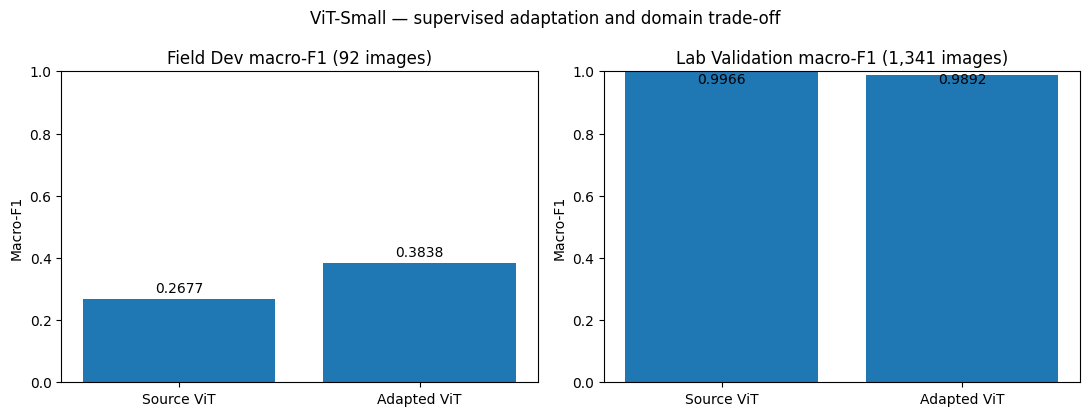

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, title, a, b in [
    (axes[0], "Field Dev macro-F1 (92 images)",
     before_field["macro_f1"], after_field["macro_f1"]),
    (axes[1], "Lab Validation macro-F1 (1,341 images)",
     before_lab["macro_f1"], after_lab["macro_f1"]),
]:
    ax.bar(["Source ViT", "Adapted ViT"], [a, b])
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Macro-F1")
    for i, val in enumerate([a, b]):
        ax.text(i, min(val + 0.02, 0.96), f"{val:.4f}", ha="center")
fig.suptitle("ViT-Small — supervised adaptation and domain trade-off")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "adaptation_comparison.png", dpi=160)
plt.show()
plt.close(fig)

In [12]:
# Optional ResNet18 comparison: require identical Field Dev manifest bytes.
resnet_root = DRIVE_ROOT / "field_adaptation_verified"
comparison_rows = []
for experiment_name in ("A1_baseline", "A2_geometric"):
    resnet_checkpoint_path = resnet_root / experiment_name / "resnet18_field_best.pt"
    resnet_summary_path = resnet_root / "adaptation_summary.csv"
    if not (resnet_checkpoint_path.is_file() and resnet_summary_path.is_file()):
        print(f"ResNet18 {experiment_name}: files not found; skipping")
        continue
    resnet_ckpt = torch.load(resnet_checkpoint_path, map_location="cpu", weights_only=True)
    if resnet_ckpt.get("field_dev_sha256") != SPLIT_HASHES["field_dev"]:
        print(f"ResNet18 {experiment_name}: Field Dev hash differs; comparison skipped")
        continue
    resnet_table = pd.read_csv(resnet_summary_path)
    matching = resnet_table[resnet_table["experiment"] == experiment_name]
    if len(matching) != 1:
        print(f"ResNet18 {experiment_name}: matching summary row not found; skipped")
        continue
    row = matching.iloc[0]
    comparison_rows.append({
        "model": f"ResNet18 {experiment_name}",
        "field_dev_before": float(row["before_field_dev_macro_f1"]),
        "field_dev_after": float(row["after_field_dev_macro_f1"]),
        "lab_val_before": float(row["before_lab_val_macro_f1"]),
        "lab_val_after": float(row["after_lab_val_macro_f1"]),
    })
comparison_rows.append({
    "model": "ViT-Small V1",
    "field_dev_before": before_field["macro_f1"],
    "field_dev_after": after_field["macro_f1"],
    "lab_val_before": before_lab["macro_f1"],
    "lab_val_after": after_lab["macro_f1"],
})
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(OUTPUT_ROOT / "cross_architecture_comparison.csv", index=False)
display(comparison_df.round(4))

,model,field_dev_before,field_dev_after,lab_val_before,lab_val_after
0,ResNet18 A1_baseline,0.2355,0.4119,0.9879,0.8185
1,ResNet18 A2_geometric,0.2497,0.4347,0.9753,0.7668
2,ViT-Small V1,0.2677,0.3838,0.9966,0.9892


## Results and interpretation

ViT adaptation improves the balance of class-level F1 scores without improving overall accuracy: macro-F1 increases by 0.1161 while correct predictions decrease from 37 to 36. Previously unrecognized Healthy and Bacterial Spot examples are recovered at the cost of lower recall in other classes.

The selected ViT Field Dev macro-F1 (0.3838) is lower than ResNet18 A1 (0.4119) and A2 (0.4347), while retained Lab Validation macro-F1 (0.9892) is higher than their 0.8185 and 0.7668. These observations do not isolate architecture, capacity, or preprocessing effects.

This is one run selected on 92 development images, without new independent field testing. Notebook 08 records mixed-domain fine-tuning as the completed source-retention comparison. Artifacts are saved under `vit_small_field_adaptation_verified/V1_lab_baseline/` and its parent Drive directory; external artifacts were not reloaded for this editorial revision.